In [1]:
import sys
import os

#####################
# Import of utils.py functions
#####################
# Required to get utils.py and access its functions
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist, interactive_MCQ

####################
# DIPY_HOME should be set prior to import of dipy to make sure all downloads point to the right folder
####################
os.environ["DIPY_HOME"] = "/home/jovyan/Data"


#############################
# Loading fsl and freesurfer within Neurodesk
# You can find the list of available other modules by clicking on the "Softwares" tab on the left
#############################
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

####################
# Setup FSL path
####################
loadFSL()

###################
# Load all relevant libraries for the lab
##################
import fsl.wrappers
from fsl.wrappers import fslmaths

import mne_nirs
import nilearn
from nilearn.datasets import fetch_development_fmri

import mne
import mne_nirs

import xml.etree.ElementTree as ET
import os.path as op
import nibabel as nib
import glob

!pip install antspyx
import ants

import openneuro
from mne.datasets import sample
from mne_bids import BIDSPath, read_raw_bids, print_dir_tree, make_report

# Useful imports to define the direct download function below
import requests
import urllib.request
from tqdm import tqdm


# FSL function wrappers which we will call from python directly
from fsl.wrappers import fast, bet
from fsl.wrappers.misc import fslroi
from fsl.wrappers import flirt

# General purpose imports to handle paths, files etc
import glob
import pandas as pd
import numpy as np
import json
fMRI_data_root = op.join(notebook_dir, 'fMRI', 'tfMRI_LANGUAGE_LR')
fMRI_data_filepath = op.join(fMRI_data_root, 'tfMRI_LANGUAGE_LR.nii.gz')

In [2]:
%gui wx


(ipykernel_launcher.py:2270): dbind-WARNING **: 14:41:39.304: Couldn't connect to accessibility bus: Failed to connect to socket /run/user/1333487151/at-spi/bus_100: No such file or directory


In [3]:
################
# Start FSLeyes (very neat tool to visualize MRI data of all sorts) within Python
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

14:41:42: Debug: Adding duplicate image handler for 'Windows bitmap file'
14:41:42: Debug: Adding duplicate animation handler for '1' type
14:41:42: Debug: Adding duplicate animation handler for '2' type
14:41:42: Debug: Adding duplicate image handler for 'Windows bitmap file'
14:41:42: Debug: Adding duplicate animation handler for '1' type
14:41:42: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:2270): Gtk-CRITICAL **: 14:41:42.784: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:2270): Gtk-CRITICAL **: 14:41:44.662: gtk_window_resize: assertion 'width > 0' failed


Text(0, 0.5, 'Mean voxel intensity')

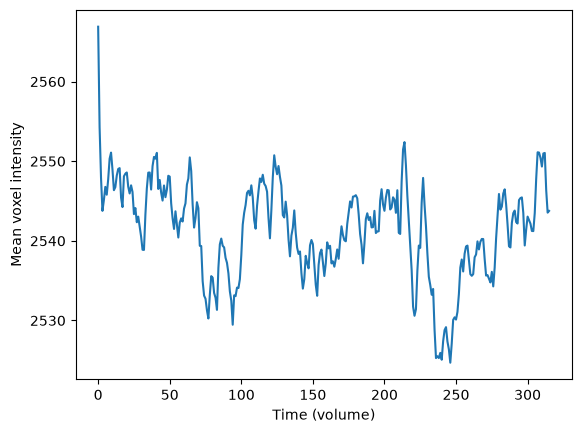

In [4]:
### Removing problematic volumes
# 1) remove first volumes, we need to see when the signal settles
import matplotlib.pyplot as plt
import nibabel as nib

plt.plot(nib.load(op.join(fMRI_data_filepath)).get_fdata().mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')